# Task 1

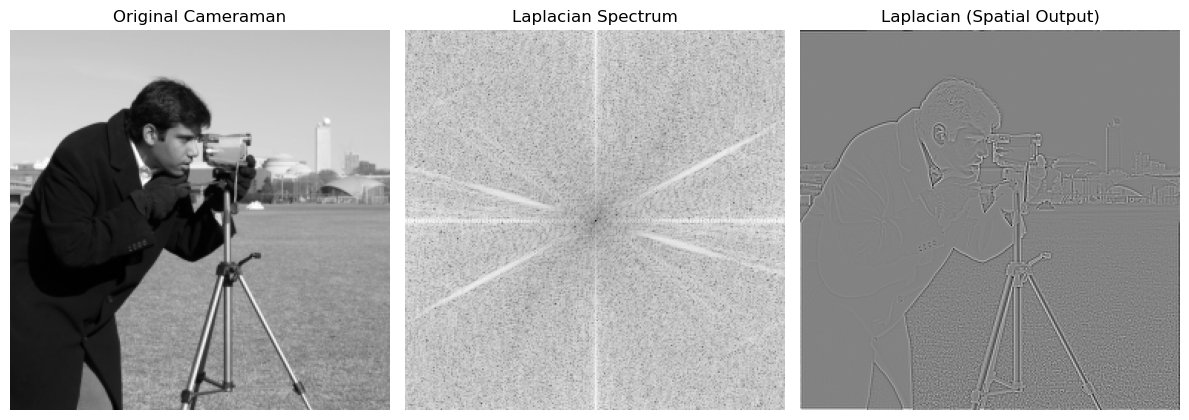

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize

image = data.camera().astype(np.float64)
image = resize(image, (256, 256), anti_aliasing=True)
M, N = image.shape
u = np.fft.fftfreq(M).reshape(-1, 1)
v = np.fft.fftfreq(N).reshape(1, -1)
laplacian_filter = -4 * (np.pi ** 2) * (u**2 + v**2)
F = np.fft.fft2(image)
F_lap = F * laplacian_filter
laplacian_image = np.fft.ifft2(F_lap).real

plt.figure(figsize=(12, 5))
plt.subplot(1, 3, 1)
plt.imshow(image, cmap="gray")
plt.title("Original Cameraman")
plt.axis("off")
plt.subplot(1, 3, 2)
plt.imshow(np.log1p(np.abs(np.fft.fftshift(F_lap))), cmap="gray")
plt.title("Laplacian Spectrum")
plt.axis("off")
plt.subplot(1, 3, 3)
plt.imshow(laplacian_image, cmap="gray")
plt.title("Laplacian (Spatial Output)")
plt.axis("off")
plt.tight_layout()
plt.show()

# Task 2

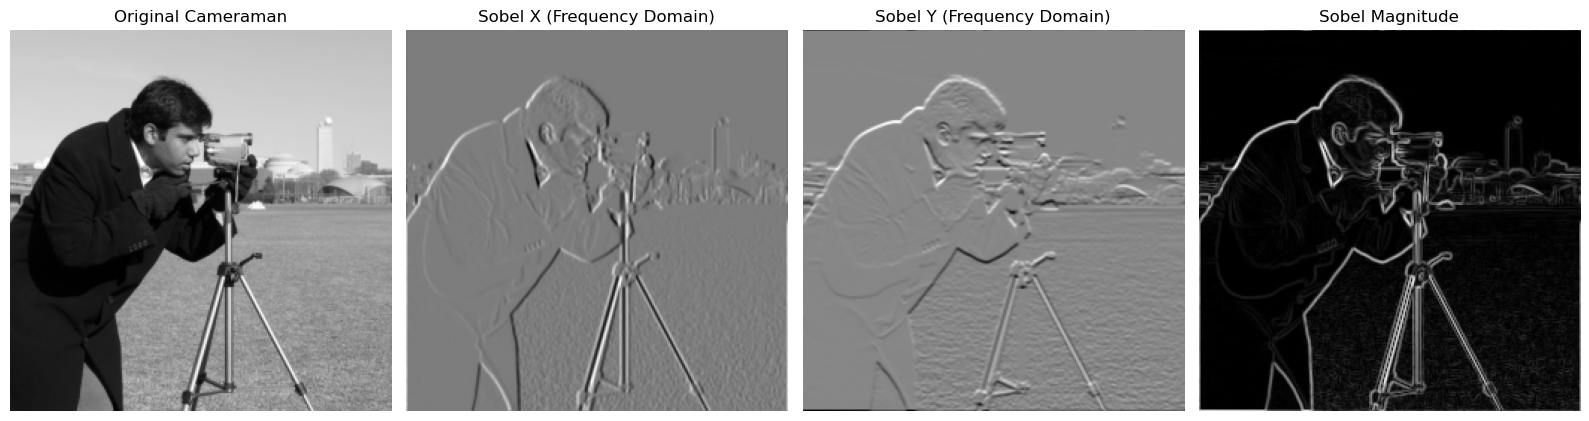

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from skimage import data
from skimage.transform import resize
from scipy.fft import fft2, ifft2, ifftshift

image = data.camera().astype(np.float64)
image = resize(image, (256, 256), anti_aliasing=True)
M, N = image.shape
sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float64)
sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float64)

def center_embed_kernel(kernel, shape):
    padded = np.zeros(shape, dtype=np.float64)
    kh, kw = kernel.shape
    ph, pw = shape
    cy, cx = ph // 2, pw // 2
    padded[cy-kh//2:cy-kh//2+kh, cx-kw//2:cx-kw//2+kw] = kernel
    return fft2(ifftshift(padded))

F = fft2(image)
H_x = center_embed_kernel(sobel_x, image.shape)
H_y = center_embed_kernel(sobel_y, image.shape)
G_x = ifft2(F * H_x).real
G_y = ifft2(F * H_y).real
magnitude = np.hypot(G_x, G_y)

fig, ax = plt.subplots(1, 4, figsize=(16, 5))
ax[0].imshow(image, cmap="gray")
ax[0].set_title("Original Cameraman")
ax[0].axis("off")
ax[1].imshow(G_x, cmap="gray")
ax[1].set_title("Sobel X (Frequency Domain)")
ax[1].axis("off")
ax[2].imshow(G_y, cmap="gray")
ax[2].set_title("Sobel Y (Frequency Domain)")
ax[2].axis("off")
ax[3].imshow(magnitude, cmap="gray")
ax[3].set_title("Sobel Magnitude")
ax[3].axis("off")
plt.tight_layout()
plt.show()